# Music Data Analysis

This analysis covers three questions:

- How are audio features distributed across the songs in this sample?
- Which tracks have similar audio profiles?
- Can audio features help classify popularity for artists outside the training set?

The data comes from [Music Genre Classification on Kaggle](https://www.kaggle.com/datasets/purumalgi/music-genre-classification),
uploaded by Purushottam Malgi from a MachineHack exercise. The CSV here is an adapted
795-record extract. Its selection and transformation steps were not preserved.

Run all cells from a fresh kernel with `music-data.csv` in the working directory.
Charts are saved in `assets/` and result tables in `results/`.

In [1]:
from pathlib import Path
import importlib.metadata
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.base import clone
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    silhouette_score, adjusted_rand_score, accuracy_score,
    balanced_accuracy_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay,
)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
ASSETS = Path('assets')
RESULTS = Path('results')
ASSETS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', palette='colorblind', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
versions = {
    package: importlib.metadata.version(package)
    for package in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn']
}
print(f'Python {platform.python_version()}')
display(pd.Series(versions, name='version').to_frame())

Python 3.12.14


,version
numpy,2.3.5
pandas,2.2.3
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
seaborn,0.13.2


## 1. Inspect and validate the data

Start with the schema, missing values and numeric ranges. Exact duplicate rows are removed
from the working copy; the original CSV stays unchanged. Repeated artist/title pairs with
different values are kept for inspection.

The Kaggle card describes genre-labelled training data and unlabelled test data, including
`instrumentalness`. Our CSV omits `instrumentalness` and genre `Class`, and includes
`release_year`, which is absent from the source card's documented schema. Its origin has
not been verified, so decade plots are provisional descriptions of local metadata.
Kaggle lists the licence as **Other (specified in description)**; no standard open-data
licence is assumed for this adapted file.

In [2]:
raw = pd.read_csv('music-data.csv')
expected_columns = [
    'Artist Name', 'Track Name', 'popularity', 'danceability', 'energy', 'key',
    'loudness', 'mode', 'speechiness', 'acousticness', 'liveness', 'valence',
    'tempo', 'duration_in min/ms', 'time_signature', 'release_year',
]
if list(raw.columns) != expected_columns:
    raise ValueError('Unexpected CSV schema. Inspect the columns before continuing.')
if raw.empty or raw.isna().any().any():
    raise ValueError('The CSV is empty or has missing values. Inspect it before analysis.')
for column in ['Artist Name', 'Track Name']:
    if not raw[column].map(lambda value: isinstance(value, str) and bool(value.strip())).all():
        raise ValueError(f'Empty or invalid text in {column}.')
numeric_columns = expected_columns[2:]
if not all(pd.api.types.is_numeric_dtype(raw[column]) for column in numeric_columns):
    raise ValueError('A numeric column contains non-numeric values.')
if not np.isfinite(raw[numeric_columns].to_numpy(dtype=float)).all():
    raise ValueError('Numeric values must be finite.')
bounded_features = ['danceability', 'energy', 'speechiness', 'acousticness', 'liveness', 'valence']
if not raw[bounded_features].apply(lambda column: column.between(0, 1)).all().all():
    raise ValueError('An audio descriptor falls outside its expected [0, 1] range.')
if not raw['popularity'].between(0, 100).all():
    raise ValueError('Popularity scores must fall within [0, 100] for this experiment.')
if not (raw[['tempo', 'duration_in min/ms']] > 0).all().all():
    raise ValueError('Tempo and duration must be positive.')
if not (raw['release_year'] % 1 == 0).all():
    raise ValueError('Release years must be integers.')

duplicate_count = int(raw.duplicated().sum())
df = raw.drop_duplicates().reset_index(drop=True).copy()
repeated_tracks = df[df.duplicated(['Artist Name', 'Track Name'], keep=False)]
print(f'Input: {len(raw)} records, {len(raw.columns)} columns; missing cells: {raw.isna().sum().sum()}')
print(f'Removed {duplicate_count} exact duplicates; retained {len(df)} records.')
print('Remaining repeated artist/title rows:')
display(repeated_tracks[['Artist Name', 'Track Name', 'release_year', 'popularity']])
display(df.head())

Input: 795 records, 16 columns; missing cells: 0
Removed 3 exact duplicates; retained 792 records.
Remaining repeated artist/title rows:


,Artist Name,Track Name,release_year,popularity
440,Beach Bunny,Ms. California,2018,51.0
441,Beach Bunny,Ms. California,2020,51.0


,Artist Name,Track Name,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,liveness,valence,tempo,duration_in min/ms,time_signature,release_year
0,Nathan Goshen,26,39.0,0.471,0.832,1.0,-5.606,0,0.1200,0.03330,0.0937,0.679,193.946,197773.0,4,2019
1,Ohmme,3 2 4 3,31.0,0.449,0.684,7.0,-8.116,1,0.0358,0.09250,0.1040,0.306,129.585,245506.0,1,2020
2,The Black Crowes,30 Days In The Hole,41.0,0.566,0.895,9.0,-4.056,1,0.0406,0.05630,0.1510,0.702,120.118,226720.0,4,1999
3,3d Blast,3rD BEST,32.0,0.377,0.773,4.0,-7.417,1,0.0732,0.04810,0.8700,0.548,119.883,242817.0,4,2018
4,Seddy Hendrinx,45 (feat. A Boogie Wit da Hoodie),51.0,0.861,0.582,10.0,-8.078,1,0.2260,0.00621,0.1030,0.607,85.007,155224.0,4,2020


The remaining repeated artist/title pair has conflicting release years. Without a source
we cannot decide which year is correct, so both records remain. Artist grouping in the
classification section keeps these records together during splitting. Artist strings
are only approximate identities; collaborations and aliases can still overlap.

Some titles contain apparent encoding damage. We preserve them rather than guess a repair.
We interpret `duration_in min/ms` as milliseconds because its magnitudes are consistent
with that unit; this assumption needs confirmation from the original source.

In [3]:
df['duration_min'] = df['duration_in min/ms'] / 60_000
df['decade'] = (df['release_year'].astype(int) // 10) * 10
numerical_features = [
    'popularity', 'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'liveness', 'valence', 'tempo', 'duration_min',
]
display(df[numerical_features].describe().round(3).T)

,count,mean,std,min,25%,50%,75%,max
popularity,792.0,46.076,16.701,1.000,35.000,45.000,58.000,94.000
danceability,792.0,0.535,0.163,0.076,0.431,0.534,0.643,0.957
energy,792.0,0.679,0.231,0.029,0.537,0.712,0.876,1.000
loudness,792.0,-7.498,3.655,-25.040,-9.206,-6.703,-4.941,0.878
speechiness,792.0,0.076,0.073,0.023,0.036,0.049,0.084,0.565
acousticness,792.0,0.218,0.301,0.000,0.004,0.052,0.351,0.995
liveness,792.0,0.203,0.164,0.017,0.099,0.133,0.276,0.990
valence,792.0,0.494,0.235,0.022,0.307,0.486,0.683,0.978
tempo,792.0,123.598,29.922,50.827,99.620,121.953,143.195,208.648
duration_min,792.0,4.324,1.987,1.677,3.240,3.819,4.903,33.323


## 2. Explore distributions and decade coverage

First inspect how the sample is distributed. Older decades with very few records cannot
support reliable comparisons. The second chart restricts decade means to groups with at
least 20 records. This is a descriptive display rule, not a statistical significance test.

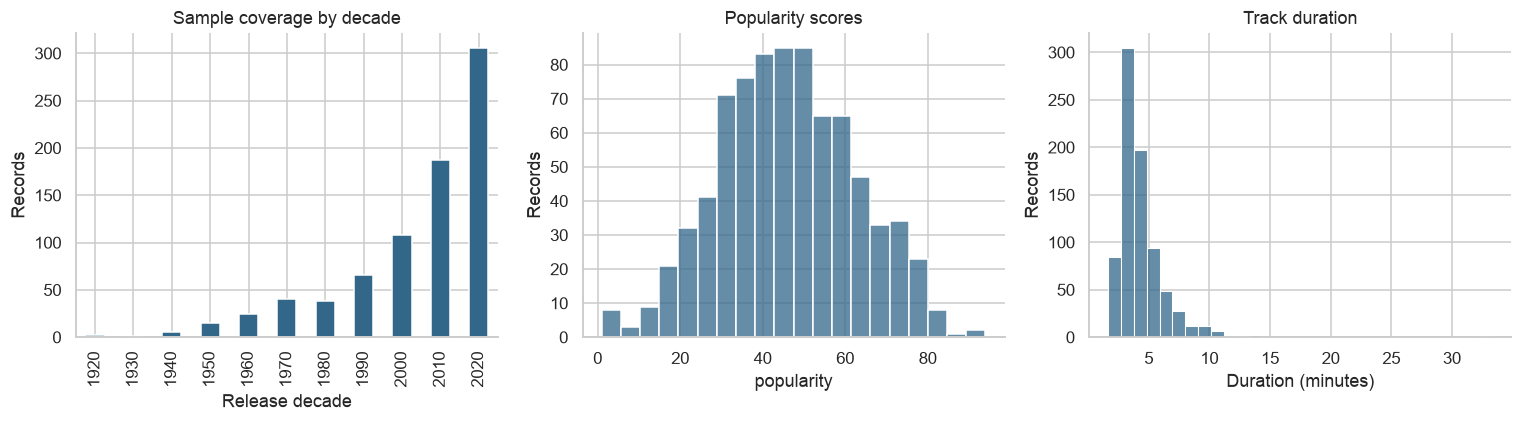

,records
decade,
1920,2
1930,1
1940,5
1950,15
1960,24
1970,40
1980,38
1990,66
2000,108


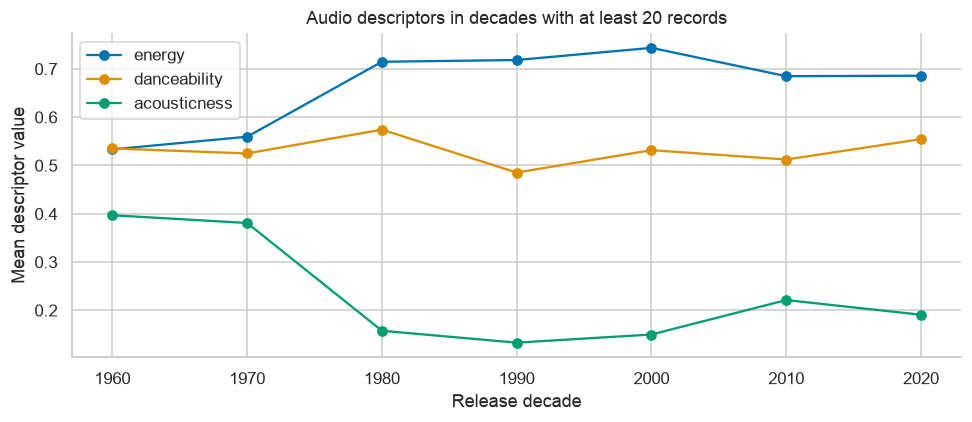

In [4]:
decade_counts = df.groupby('decade').size().rename('records')
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
decade_counts.plot.bar(ax=axes[0], color='#32678a')
axes[0].set(title='Sample coverage by decade', xlabel='Release decade', ylabel='Records')
sns.histplot(data=df, x='popularity', bins=20, ax=axes[1], color='#32678a')
axes[1].set(title='Popularity scores', ylabel='Records')
sns.histplot(data=df, x='duration_min', bins=30, ax=axes[2], color='#32678a')
axes[2].set(title='Track duration', xlabel='Duration (minutes)', ylabel='Records')
fig.tight_layout()
fig.savefig(ASSETS / 'sample_overview.png', dpi=150)
plt.show()
display(decade_counts.to_frame())

eligible_decades = decade_counts[decade_counts >= 20].index
decade_means = df.groupby('decade')[['energy', 'danceability', 'acousticness']].mean()
fig, ax = plt.subplots(figsize=(9, 4))
decade_means.loc[eligible_decades].plot(marker='o', ax=ax)
ax.set(title='Audio descriptors in decades with at least 20 records',
       xlabel='Release decade', ylabel='Mean descriptor value')
fig.tight_layout()
plt.show()

We use Pearson correlations to describe associations in the sample. Correlation does
not establish why a song is popular or how music production changed historically.

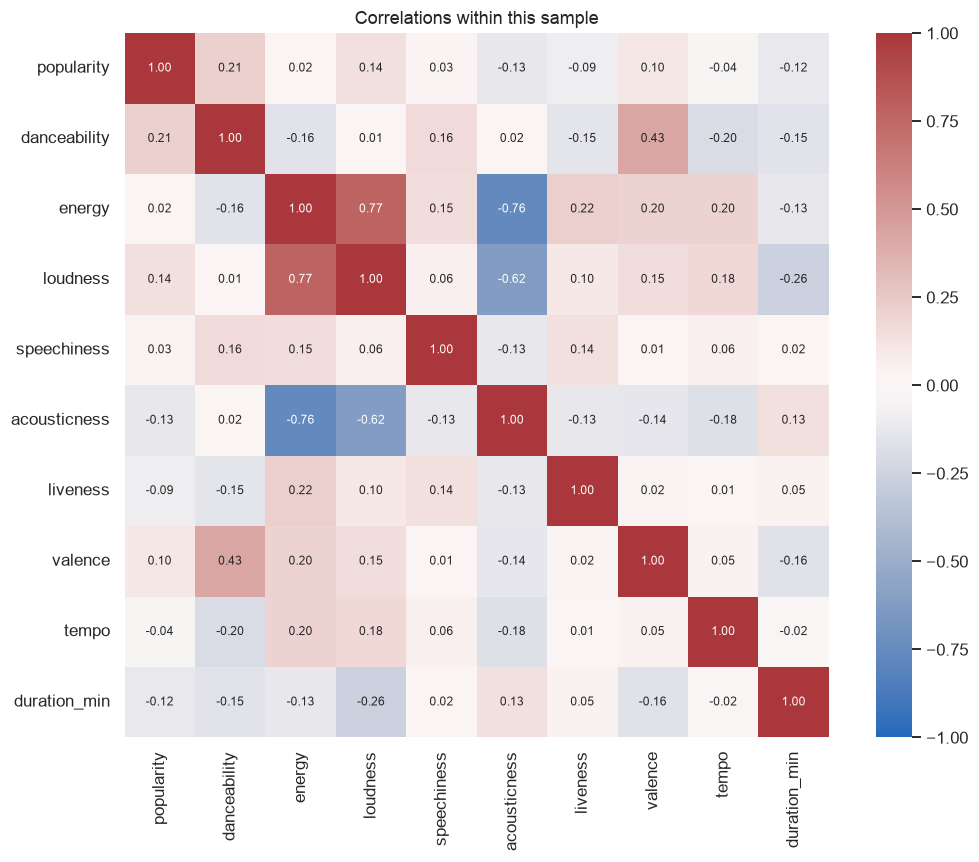

In [5]:
correlations = df[numerical_features].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='vlag', center=0,
            vmin=-1, vmax=1, square=True, ax=ax, annot_kws={'size': 8})
ax.set_title('Correlations within this sample')
fig.tight_layout()
fig.savefig(ASSETS / 'correlations.png', dpi=150)
plt.show()

## 3. Inspect outliers without deleting them

The interquartile range rule flags observations outside Q1 - 1.5 × IQR and Q3 + 1.5 × IQR.
A long track can be a valid recording. We retain flagged records because this rule alone
does not demonstrate a data error.

In [6]:
outlier_rows = []
for feature in ['tempo', 'popularity', 'energy', 'duration_min']:
    q1, q3 = df[feature].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = ~df[feature].between(lower, upper)
    outlier_rows.append({'feature': feature, 'lower': lower, 'upper': upper,
                         'flagged_records': int(mask.sum())})
outlier_summary = pd.DataFrame(outlier_rows).set_index('feature')
display(outlier_summary.round(3))
display(df.nlargest(5, 'duration_min')[['Artist Name', 'Track Name', 'duration_min']])

,lower,upper,flagged_records
feature,,,
tempo,34.256,208.559,1
popularity,0.500,92.500,1
energy,0.029,1.384,0
duration_min,0.746,7.398,50


,Artist Name,Track Name,duration_min
356,"Rekha, Vinod Khanna, Ram P. Sethi",Kahiye Zohara Begum (with Dialogues),33.322583
573,Prem Joshua,Shiva Moon (Prem Joshua & Maneesh de Moor's Mo...,13.739638
375,King Crimson,Larks' Tongues In Aspic (Part I),13.594583
557,"Sonu Nigam, Kavita Krishnamurthy",Satarangi Re,12.375555
640,"KK, Dominique",Tadap Tadap,11.049250


## 4. Select and interpret song clusters

Clustering uses danceability, energy, valence and tempo. Standardisation prevents BPM
from dominating distance simply because it has a larger numeric scale. Popularity is
excluded from clustering; we can describe it afterwards without defining the groups by it.

We compare k=2 through k=10 and choose the highest average silhouette score in this range.
The inertia curve provides context. This choice is an exploratory heuristic: it does not
prove that the catalogue has a true number of musical styles.

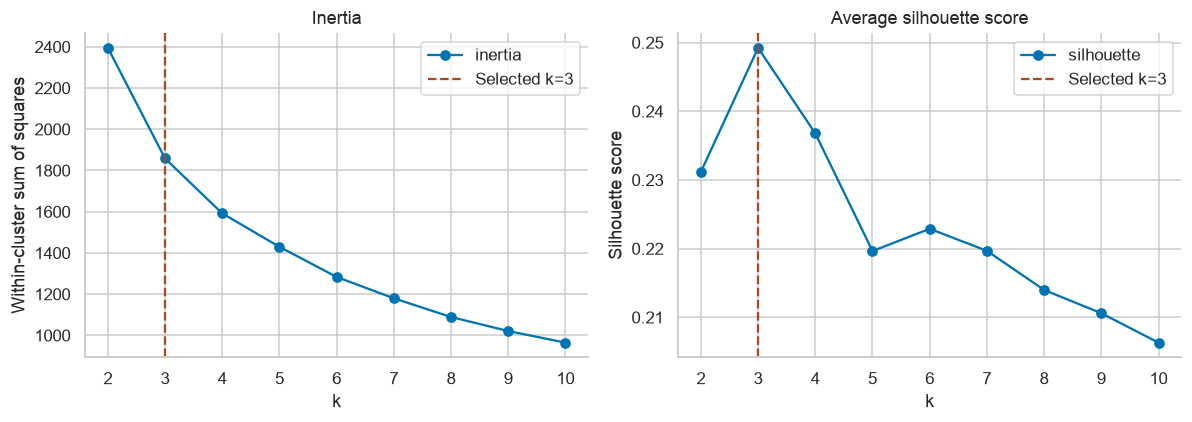

,inertia,silhouette
k,,
2,2394.7272,0.2312
3,1858.0030,0.2492
4,1591.5381,0.2368
5,1429.3803,0.2196
6,1283.2153,0.2229
7,1179.5825,0.2197
8,1088.9312,0.2140
9,1020.9012,0.2106
10,964.5674,0.2063


Selected k=3; silhouette=0.249


In [7]:
cluster_features = ['danceability', 'energy', 'valence', 'tempo']
scaler = StandardScaler()
X_cluster = scaler.fit_transform(df[cluster_features])
cluster_candidates = {}
cluster_rows = []
for k in range(2, 11):
    candidate = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_cluster)
    score = silhouette_score(X_cluster, candidate.labels_)
    cluster_candidates[k] = candidate
    cluster_rows.append({'k': k, 'inertia': candidate.inertia_, 'silhouette': score})
cluster_scores = pd.DataFrame(cluster_rows).set_index('k')
selected_k = int(cluster_scores['silhouette'].idxmax())
kmeans = cluster_candidates[selected_k]
cluster_labels = kmeans.labels_
assert len(np.unique(cluster_labels)) == selected_k
assert selected_k == int(cluster_scores['silhouette'].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cluster_scores['inertia'].plot(marker='o', ax=axes[0])
cluster_scores['silhouette'].plot(marker='o', ax=axes[1])
axes[0].set(title='Inertia', ylabel='Within-cluster sum of squares')
axes[1].set(title='Average silhouette score', ylabel='Silhouette score')
for ax in axes:
    ax.axvline(selected_k, color='#a34a28', linestyle='--', label=f'Selected k={selected_k}')
    ax.legend()
fig.tight_layout()
plt.show()
display(cluster_scores.round(4))
print(f'Selected k={selected_k}; silhouette={cluster_scores.loc[selected_k, "silhouette"]:.3f}')

,records,danceability,energy,valence,tempo,popularity
cluster,,,,,,
0,297,0.657,0.708,0.706,116.995,49.054
1,200,0.531,0.403,0.306,109.685,45.700
2,295,0.415,0.837,0.409,139.679,43.332


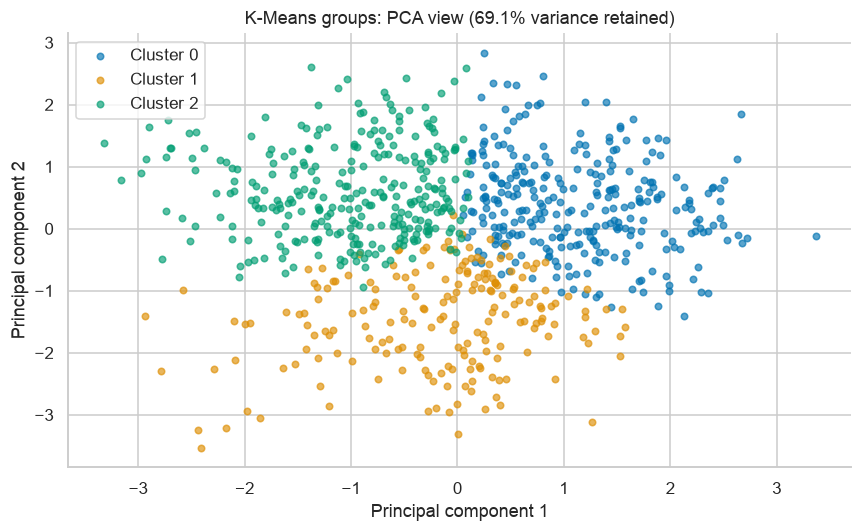

In [8]:
cluster_summary = df.assign(cluster=cluster_labels).groupby('cluster')[
    cluster_features + ['popularity']
].mean()
cluster_summary.insert(0, 'records', pd.Series(cluster_labels).value_counts().sort_index())
display(cluster_summary.round(3))

pca = PCA(n_components=2)
projection = pca.fit_transform(X_cluster)
pca_variance = float(pca.explained_variance_ratio_.sum())
fig, ax = plt.subplots(figsize=(8, 5))
for label in range(selected_k):
    points = projection[cluster_labels == label]
    ax.scatter(points[:, 0], points[:, 1], s=18, alpha=0.65, label=f'Cluster {label}')
ax.set(title=f'K-Means groups: PCA view ({pca_variance:.1%} variance retained)',
       xlabel='Principal component 1', ylabel='Principal component 2')
ax.legend()
fig.tight_layout()
fig.savefig(ASSETS / 'song_clusters.png', dpi=150)
plt.show()

PCA is a two-dimensional projection for inspection; overlap here does not completely
describe distances in the four clustering features. Cluster numbers are arbitrary labels.
The table above describes their audio profiles without assigning genre names.

### Compare with hierarchical clustering

On a fixed 100-record sample we fit both methods to exactly the same standardised features.
Adjusted Rand Index (ARI) measures agreement independently of the numeric cluster labels.
Agreement is a comparison between methods, rather than evidence of a correct segmentation.

Adjusted Rand Index on 100 records: 0.546


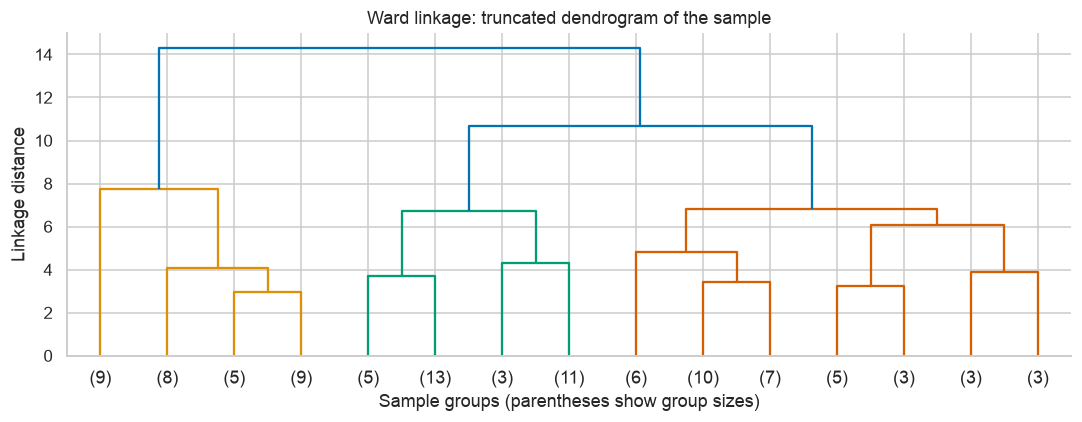

In [9]:
sample_positions = np.random.default_rng(SEED).choice(len(df), size=min(100, len(df)), replace=False)
X_sample = X_cluster[sample_positions]
sample_kmeans = KMeans(n_clusters=selected_k, n_init=10, random_state=SEED).fit_predict(X_sample)
hierarchical_labels = AgglomerativeClustering(n_clusters=selected_k, linkage='ward').fit_predict(X_sample)
agreement = adjusted_rand_score(sample_kmeans, hierarchical_labels)
print(f'Adjusted Rand Index on {len(sample_positions)} records: {agreement:.3f}')
fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(linkage(X_sample, method='ward'), truncate_mode='lastp', p=15, ax=ax)
ax.set(title='Ward linkage: truncated dendrogram of the sample',
       xlabel='Sample groups (parentheses show group sizes)', ylabel='Linkage distance')
fig.tight_layout()
plt.show()

## 5. Evaluate popularity classification on held-out artists

**Class 1 means a recorded popularity score strictly above 50**. A fixed threshold keeps
the label definition independent of the test set. This is a working definition for the
exercise, rather than a claim about future hits.

We reserve 20% of distinct artist strings for testing using one fixed grouped split;
the percentage of records may differ. We then compare models on the training partition
with five-fold stratified group cross-validation. Artist strings never cross a training
and validation/test boundary. We show class distributions because group splits cannot
guarantee identical class proportions.

The eight predictors are audio descriptors only. We exclude popularity, artist, title,
release year, PCA coordinates and cluster assignments. The selected models do not require
scaling, and the earlier exploratory scaler is never used in classification.

In [10]:
POPULARITY_THRESHOLD = 50
classification_features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'liveness', 'valence', 'tempo',
]
X = df[classification_features]
y = (df['popularity'] > POPULARITY_THRESHOLD).astype(int)
artists = df['Artist Name'].str.strip().str.casefold()
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(split.split(X, y, groups=artists))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_artists, test_artists = artists.iloc[train_idx], artists.iloc[test_idx]
assert set(train_artists).isdisjoint(set(test_artists)), 'Artist leakage into test data'
assert set(train_idx).isdisjoint(set(test_idx))
assert len(train_idx) + len(test_idx) == len(df)
assert y_train.nunique() == y_test.nunique() == 2
assert 'popularity' not in X.columns

split_summary = pd.DataFrame({
    'records': [len(y_train), len(y_test)],
    'artist_groups': [train_artists.nunique(), test_artists.nunique()],
    'class_0': [int((y_train == 0).sum()), int((y_test == 0).sum())],
    'class_1': [int(y_train.sum()), int(y_test.sum())],
}, index=['Training', 'Test'])
display(split_summary)

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train, groups=train_artists))
for fold_train, fold_valid in cv_splits:
    assert set(train_artists.iloc[fold_train]).isdisjoint(set(train_artists.iloc[fold_valid]))
    assert y_train.iloc[fold_train].nunique() == y_train.iloc[fold_valid].nunique() == 2

,records,artist_groups,class_0,class_1
Training,641,588,377,264
Test,151,147,103,48


We compare Decision Tree, Random Forest and Gaussian Naive Bayes.
A majority-class dummy classifier supplies a baseline. Balanced accuracy averages recall
across the two classes, so a model that always predicts one class scores 0.5 here.

We select the trained model with the highest mean cross-validation balanced accuracy.
The standard deviation describes variation between folds; it is not a confidence interval.
We do not search hyperparameters or use test scores to choose the model.

In [11]:
models = {
    'Majority baseline': DummyClassifier(strategy='most_frequent'),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1),
    'Gaussian Naive Bayes': GaussianNB(),
}
cv_rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv_splits,
        scoring={'accuracy': 'accuracy', 'balanced_accuracy': 'balanced_accuracy'},
        n_jobs=1, error_score='raise',
    )
    cv_rows.append({
        'model': name,
        'accuracy_mean': scores['test_accuracy'].mean(),
        'balanced_accuracy_mean': scores['test_balanced_accuracy'].mean(),
        'balanced_accuracy_std': scores['test_balanced_accuracy'].std(ddof=1),
    })
cv_results = pd.DataFrame(cv_rows).set_index('model')
selected_model_name = cv_results.drop(index='Majority baseline')['balanced_accuracy_mean'].idxmax()
display(cv_results.sort_values('balanced_accuracy_mean', ascending=False).round(4))
print(f'Selected trained model using training CV only: {selected_model_name}')

,accuracy_mean,balanced_accuracy_mean,balanced_accuracy_std
model,,,
Gaussian Naive Bayes,0.5849,0.5827,0.0269
Random Forest,0.5741,0.5373,0.0398
Decision Tree,0.5459,0.5273,0.0539
Majority baseline,0.5881,0.5000,0.0000


Selected trained model using training CV only: Gaussian Naive Bayes


### Final test evaluation

We now fit the selected trained model and the dummy baseline on all training records,
then evaluate them on the held-out artist groups. The test set has not been used in
fitting or model selection. We report accuracy, balanced accuracy, F1 for class 1 and
ROC AUC, alongside a confusion matrix and per-class precision/recall.

This is an exploratory reanalysis of an already-inspected dataset, not an external or
prospective validation. One split cannot establish how well the model will generalise
to another music catalogue or a later collection date.

,accuracy,balanced_accuracy,f1,roc_auc
model,,,,
Majority baseline,0.6821,0.500,0.0,0.5000
Gaussian Naive Bayes,0.6026,0.553,0.4,0.6313


              precision    recall  f1-score   support

 Score <= 50       0.72      0.69      0.70       103
  Score > 50       0.38      0.42      0.40        48

    accuracy                           0.60       151
   macro avg       0.55      0.55      0.55       151
weighted avg       0.61      0.60      0.61       151



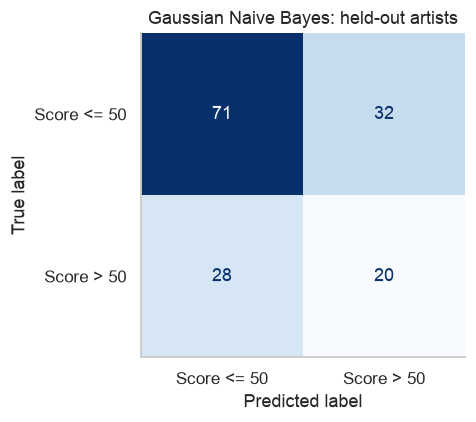

In [12]:
test_rows = []
fitted_models = {}
for name in ['Majority baseline', selected_model_name]:
    model = clone(models[name]).fit(X_train, y_train)
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
    fitted_models[name] = model
    test_rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test, prediction),
        'balanced_accuracy': balanced_accuracy_score(y_test, prediction),
        'f1': f1_score(y_test, prediction, zero_division=0),
        'roc_auc': roc_auc_score(y_test, probability),
    })
test_results = pd.DataFrame(test_rows).set_index('model')
assert np.isfinite(test_results.to_numpy()).all()
assert test_results.ge(0).all().all() and test_results.le(1).all().all()
selected_prediction = fitted_models[selected_model_name].predict(X_test)
display(test_results.round(4))
print(classification_report(y_test, selected_prediction,
                            target_names=['Score <= 50', 'Score > 50'], zero_division=0))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, selected_prediction, display_labels=['Score <= 50', 'Score > 50'],
    cmap='Blues', colorbar=False, ax=ax,
)
ax.grid(False)
ax.set_title(f'{selected_model_name}: held-out artists')
fig.tight_layout()
fig.savefig(ASSETS / 'test_confusion_matrix.png', dpi=150)
plt.show()

## 6. Results and limitations

The summary below uses the calculated results. Tables are also saved as CSV files,
together with a JSON summary used for the README.

In [13]:
test_score = float(test_results.loc[selected_model_name, 'balanced_accuracy'])
baseline_score = float(test_results.loc['Majority baseline', 'balanced_accuracy'])
difference = test_score - baseline_score
comparison = 'above' if difference > 0 else 'below' if difference < 0 else 'equal to'
summary = {
    'raw_records': len(raw),
    'analysis_records': len(df),
    'exact_duplicates_removed': duplicate_count,
    'unresolved_repeated_track_groups': len(repeated_tracks[['Artist Name', 'Track Name']].drop_duplicates()),
    'year_min': int(df['release_year'].min()),
    'year_max': int(df['release_year'].max()),
    'share_since_2000': float((df['release_year'] >= 2000).mean()),
    'popularity_threshold': POPULARITY_THRESHOLD,
    'selected_k': selected_k,
    'silhouette': float(cluster_scores.loc[selected_k, 'silhouette']),
    'pca_variance_retained': pca_variance,
    'hierarchical_ari': float(agreement),
    'selected_model': selected_model_name,
    'train_records': len(y_train),
    'test_records': len(y_test),
    'train_artist_groups': int(train_artists.nunique()),
    'test_artist_groups': int(test_artists.nunique()),
    'cv_results': cv_results.reset_index().to_dict(orient='records'),
    'test_results': test_results.reset_index().to_dict(orient='records'),
    'correlations': {
        'energy_loudness': float(correlations.loc['energy', 'loudness']),
        'energy_acousticness': float(correlations.loc['energy', 'acousticness']),
    },
    'python': platform.python_version(),
    'versions': versions,
}
cluster_scores.to_csv(RESULTS / 'clustering_scores.csv')
cluster_summary.to_csv(RESULTS / 'cluster_profiles.csv')
cv_results.to_csv(RESULTS / 'cross_validation.csv')
test_results.to_csv(RESULTS / 'test_metrics.csv')
split_summary.to_csv(RESULTS / 'data_split.csv')
(RESULTS / 'summary.json').write_text(json.dumps(summary, indent=2) + '\n')

display(Markdown(f'''
- **Data:** {len(raw)} input records; {duplicate_count} exact duplicates removed;
  {len(df)} records analysed. {summary['share_since_2000']:.1%} date from 2000 onwards.
- **Associations:** energy/loudness r={correlations.loc['energy', 'loudness']:.3f};
  energy/acousticness r={correlations.loc['energy', 'acousticness']:.3f} in this sample.
  These are associations, not causal effects.
- **Clustering:** the best silhouette among the tested values selects k={selected_k}
  (score {summary['silhouette']:.3f}). The PCA view retains {pca_variance:.1%} of variance.
  We treat these as exploratory groups, not established genres.
- **Classification:** training-only cross-validation selects {selected_model_name}.
  Its held-out balanced accuracy is {test_score:.1%}, {comparison} the baseline's
  {baseline_score:.1%} ({difference * 100:+.1f} percentage points).
  This single split does not demonstrate a reliable advantage across catalogues.
'''))


- **Data:** 795 input records; 3 exact duplicates removed;
  792 records analysed. 75.9% date from 2000 onwards.
- **Associations:** energy/loudness r=0.774;
  energy/acousticness r=-0.764 in this sample.
  These are associations, not causal effects.
- **Clustering:** the best silhouette among the tested values selects k=3
  (score 0.249). The PCA view retains 69.1% of variance.
  We treat these as exploratory groups, not established genres.
- **Classification:** training-only cross-validation selects Gaussian Naive Bayes.
  Its held-out balanced accuracy is 55.3%, above the baseline's
  50.0% (+5.3 percentage points).
  This single split does not demonstrate a reliable advantage across catalogues.


### What remains uncertain

- The Kaggle source is identified, but the local subset selection, transformation steps,
  collection date and origin of `release_year` are not documented. The source uses an
  unspecified licence category rather than a named standard open-data licence.
  Apparent encoding errors and the repeated track with conflicting years remain unresolved.
- The sample is small and concentrated in recent releases. Decade comparisons reflect
  this sample, not the history of music or the full output of any streaming service.
- A fixed popularity threshold is an illustrative classification task. Changing it changes
  the question; an accuracy score here does not measure the ability to discover future hits.
- Artist grouping uses normalised credited-name strings, not verified artist identifiers.
  Aliases, collaborations and alternate titles can still connect records across groups.
- We have not tested other catalogues, future periods, threshold sensitivity or cluster
  stability under resampling. A single held-out split and fold variation are not uncertainty
  estimates for deployment.

Before trying more models, the next step would be to document how the extract was prepared
and test the analysis on a larger sample.